# ⚛️ Quantum Machine Learning for Disease Classification
### A Hybrid Quantum-Classical Pipeline on the Breast Cancer Wisconsin Dataset

**Goal:** Build, evaluate, and benchmark hybrid quantum-classical machine learning models classifying malignant vs. benign patient records using:
1. **Quantum Support Vector Machine (QSVM)** with second-order Pauli-Z feature mapping (`ZZFeatureMap`).
2. **Variational Quantum Classifier (VQC)** with hardware-efficient entangling ansatz and classical Adam optimization.
3. **Classical Baselines:** Support Vector Machine (RBF kernel), Logistic Regression ($L_2$), and Random Forest.

## 1. Setup & Environment Verification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pennylane as qml
import sklearn

print(f"NumPy Version: {np.__version__}")
print(f"PennyLane Version: {qml.__version__}")
print(f"Scikit-Learn Version: {sklearn.__version__}")

NumPy Version: 2.5.4
PennyLane Version: 0.45.1
Scikit-Learn Version: 1.9.1


## 2. Dataset Exploration & Preprocessing
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains 569 instances with 30 continuous clinical features derived from digitized images of fine needle aspirates (FNA) of breast masses.

In [2]:
from src.data.preprocessor import DataPipeline

# Initialize pipeline with 4 qubits (PCA components)
pipeline = DataPipeline(n_components=4, test_size=0.2, random_state=42)
data = pipeline.fit_transform()

X_train, X_test = data["X_train"], data["X_test"]
y_train, y_test = data["y_train"], data["y_test"]

print(f"Training set shape: {X_train.shape} (Labels: {np.bincount(y_train)})")
print(f"Testing set shape:  {X_test.shape} (Labels: {np.bincount(y_test)})")
print(f"Explained Variance by 4 PCA components: {np.sum(pipeline.explained_variance_ratio_)*100:.2f}%")

Training set shape: (455, 4) (Labels: [170 285])
Testing set shape:  (114, 4) (Labels: [42 72])
Explained Variance by 4 PCA components: 79.63%


## 3. Quantum Feature Encoding (ZZFeatureMap)
We encode classical vectors $x \in [0, \pi]^4$ into a $2^4 = 16$-dimensional Hilbert space using the Havlíček second-order expansion:
$$U_{\Phi(x)} = \exp\left( i \sum_i x_i Z_i + i \sum_{j > i} 2(\pi - x_i)(\pi - x_j) Z_i Z_j \right)$$

In [3]:
from src.quantum.feature_maps import QuantumFeatureEncoder

encoder = QuantumFeatureEncoder(n_qubits=4, encoding_type="zz", reps=1)
sample_patient = X_train[0]
statevector = encoder.encode_to_statevector(sample_patient)

print("Quantum Circuit Schematic:")
print(encoder.get_circuit_diagram(sample_patient))
print(f"\nStatevector norm: {np.linalg.norm(statevector):.4f} (Shape: {statevector.shape})")

Quantum Circuit Schematic:
0: ──H──RZ(0.46)─╭●────────────╭●─╭●────────────╭●─╭●───────────╭●───────────────────────────── ···
1: ──H──RZ(2.58)─╰X──RZ(10.78)─╰X─│─────────────│──│────────────│──╭●───────────╭●─╭●────────── ···
2: ──H──RZ(1.83)──────────────────╰X──RZ(12.96)─╰X─│────────────│──╰X──RZ(8.25)─╰X─│─────────── ···
3: ──H──RZ(2.96)───────────────────────────────────╰X──RZ(9.66)─╰X─────────────────╰X──RZ(6.15) ···

0: ··· ────────────────────┤  State
1: ··· ─╭●─────────────────┤  State
2: ··· ─│──╭●───────────╭●─┤  State
3: ··· ─╰X─╰X──RZ(7.39)─╰X─┤  State

Statevector norm: 1.0000 (Shape: (16,))


## 4. Quantum Kernel Support Vector Machine (QSVM)
Computes the quantum transition fidelity Gram matrix: $K_{ij} = |\langle\phi(x_i)|\phi(x_j)\rangle|^2$.

In [4]:
from src.models.qsvm import QuantumKernelClassifier
import time

qsvm = QuantumKernelClassifier(n_qubits=4, encoding_type="zz", reps=1, C=1.0, random_state=42)

start = time.perf_counter()
qsvm.fit(X_train, y_train)
train_time = time.perf_counter() - start

preds_qsvm = qsvm.predict(X_test)
acc_qsvm = np.mean(preds_qsvm == y_test)
print(f"QSVM Training Time: {train_time:.3f}s | Test Accuracy: {acc_qsvm*100:.2f}%")

QSVM Training Time: 0.917s | Test Accuracy: 92.98%


## 5. Variational Quantum Classifier (VQC)
Parameterized quantum ansatz with $R_Y, R_Z$ rotations and circular CNOT entanglement, optimized via Adam.

VQC Training Time: 43.928s | Test Accuracy: 85.96%


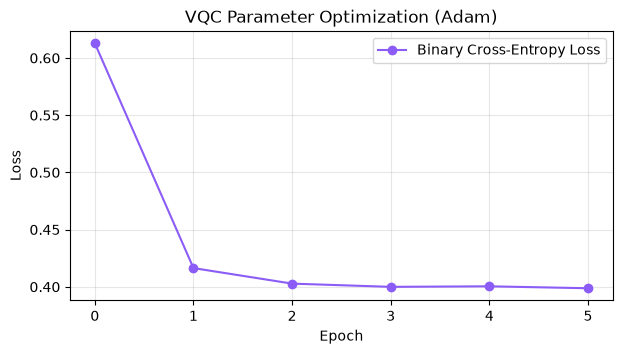

In [5]:
from src.models.vqc import VariationalQuantumClassifier

vqc = VariationalQuantumClassifier(n_qubits=4, n_layers=2, epochs=6, lr=0.05, random_state=42)

start = time.perf_counter()
history = vqc.fit(X_train, y_train)
vqc_time = time.perf_counter() - start

preds_vqc = vqc.predict(X_test)
acc_vqc = np.mean(preds_vqc == y_test)
print(f"VQC Training Time: {vqc_time:.3f}s | Test Accuracy: {acc_vqc*100:.2f}%")

# Plot training loss curve
plt.figure(figsize=(7, 3.5))
plt.plot(history["loss"], marker="o", color="#8B5CF6", label="Binary Cross-Entropy Loss")
plt.title("VQC Parameter Optimization (Adam)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 6. Classical Baselines & Full Comparative Benchmark

In [6]:
from src.evaluation.benchmark import BenchmarkRunner
from src.models.classical import get_classical_baselines

models = {
    "QSVM": qsvm,
    "VQC": vqc,
}
models.update(get_classical_baselines(random_state=42))

runner = BenchmarkRunner(
    models=models,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    class_names=["Malignant", "Benign"],
)
results = runner.run()

# Display Markdown Summary Table
print(runner.generate_summary_table())

Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC | Train Time (s) | Infer Time (s)
--- | --- | --- | --- | --- | --- | --- | ---
QSVM | 0.9298 | 0.9571 | 0.9306 | 0.9437 | 0.9686 | 0.912 | 0.243
VQC | 0.9123 | 0.8780 | 1.0000 | 0.9351 | 0.9782 | 63.709 | 0.865
Classical_SVM | 0.9561 | 0.9589 | 0.9722 | 0.9655 | 0.9924 | 0.012 | 0.001
Logistic_Regression | 0.9561 | 0.9467 | 0.9861 | 0.9660 | 0.9931 | 0.003 | 0.000
Random_Forest | 0.9211 | 0.9437 | 0.9306 | 0.9371 | 0.9869 | 0.144 | 0.006


## 7. Comparative Visualizations: ROC Curves & Confusion Matrices

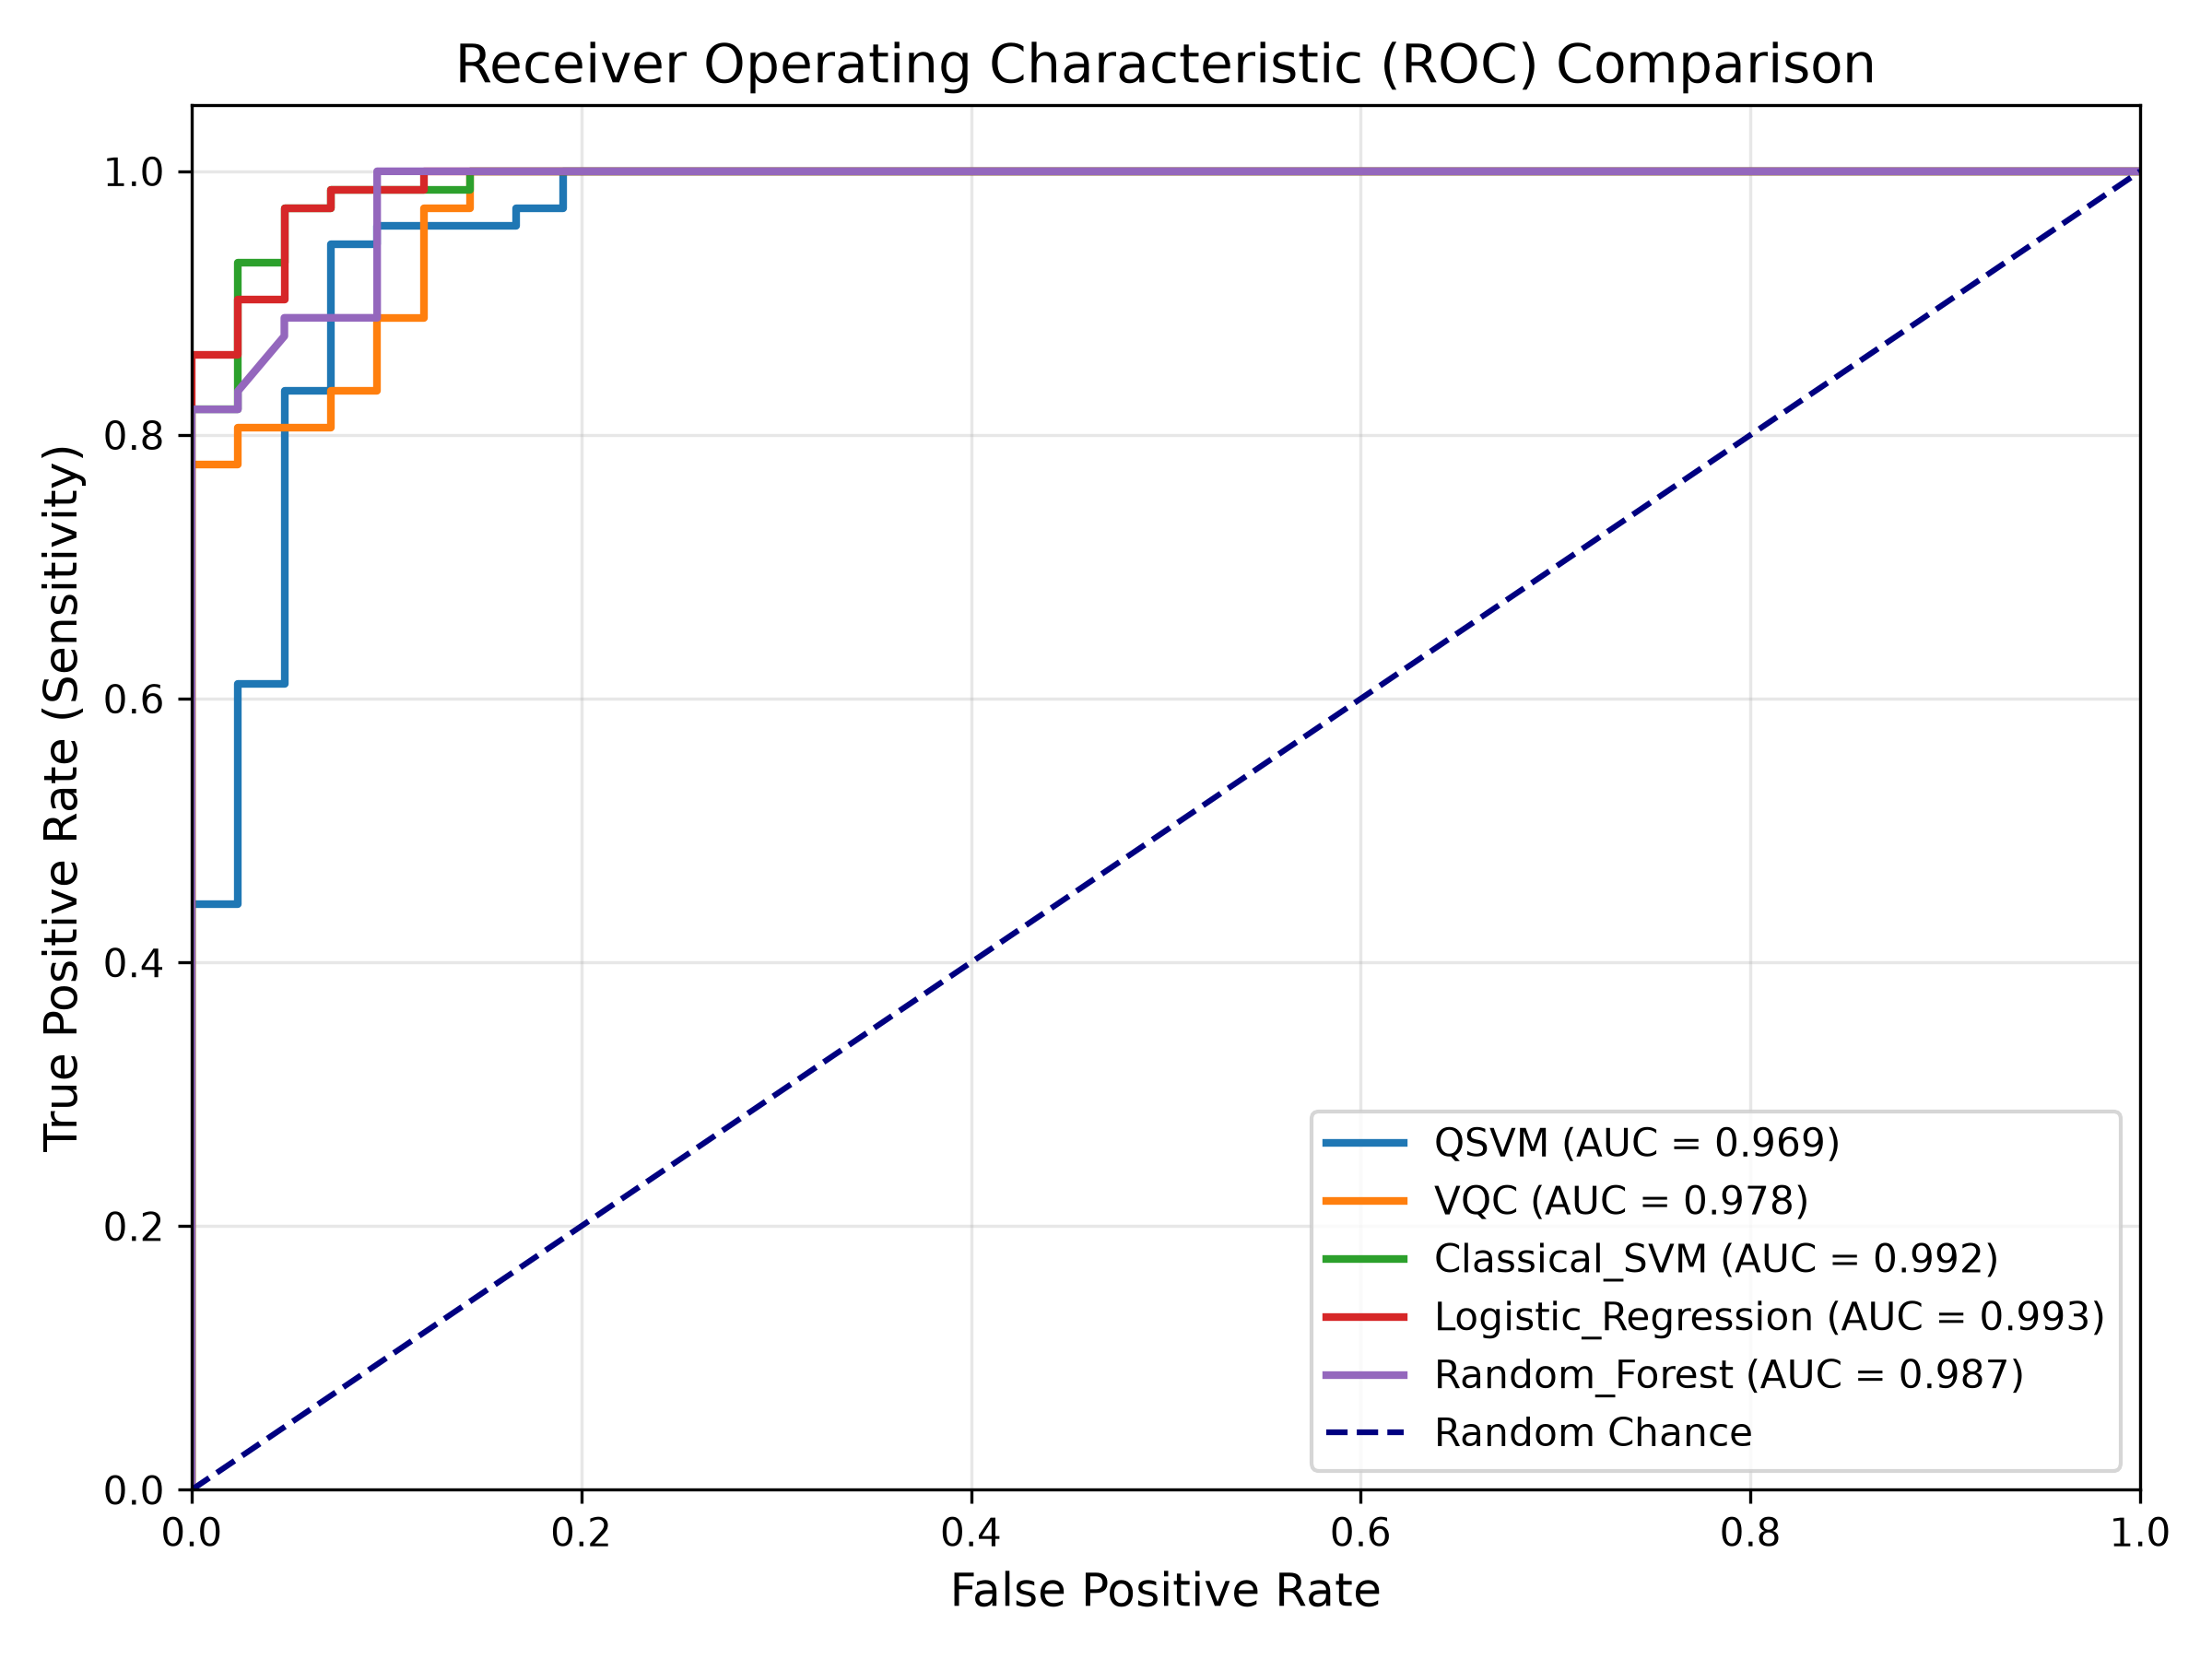

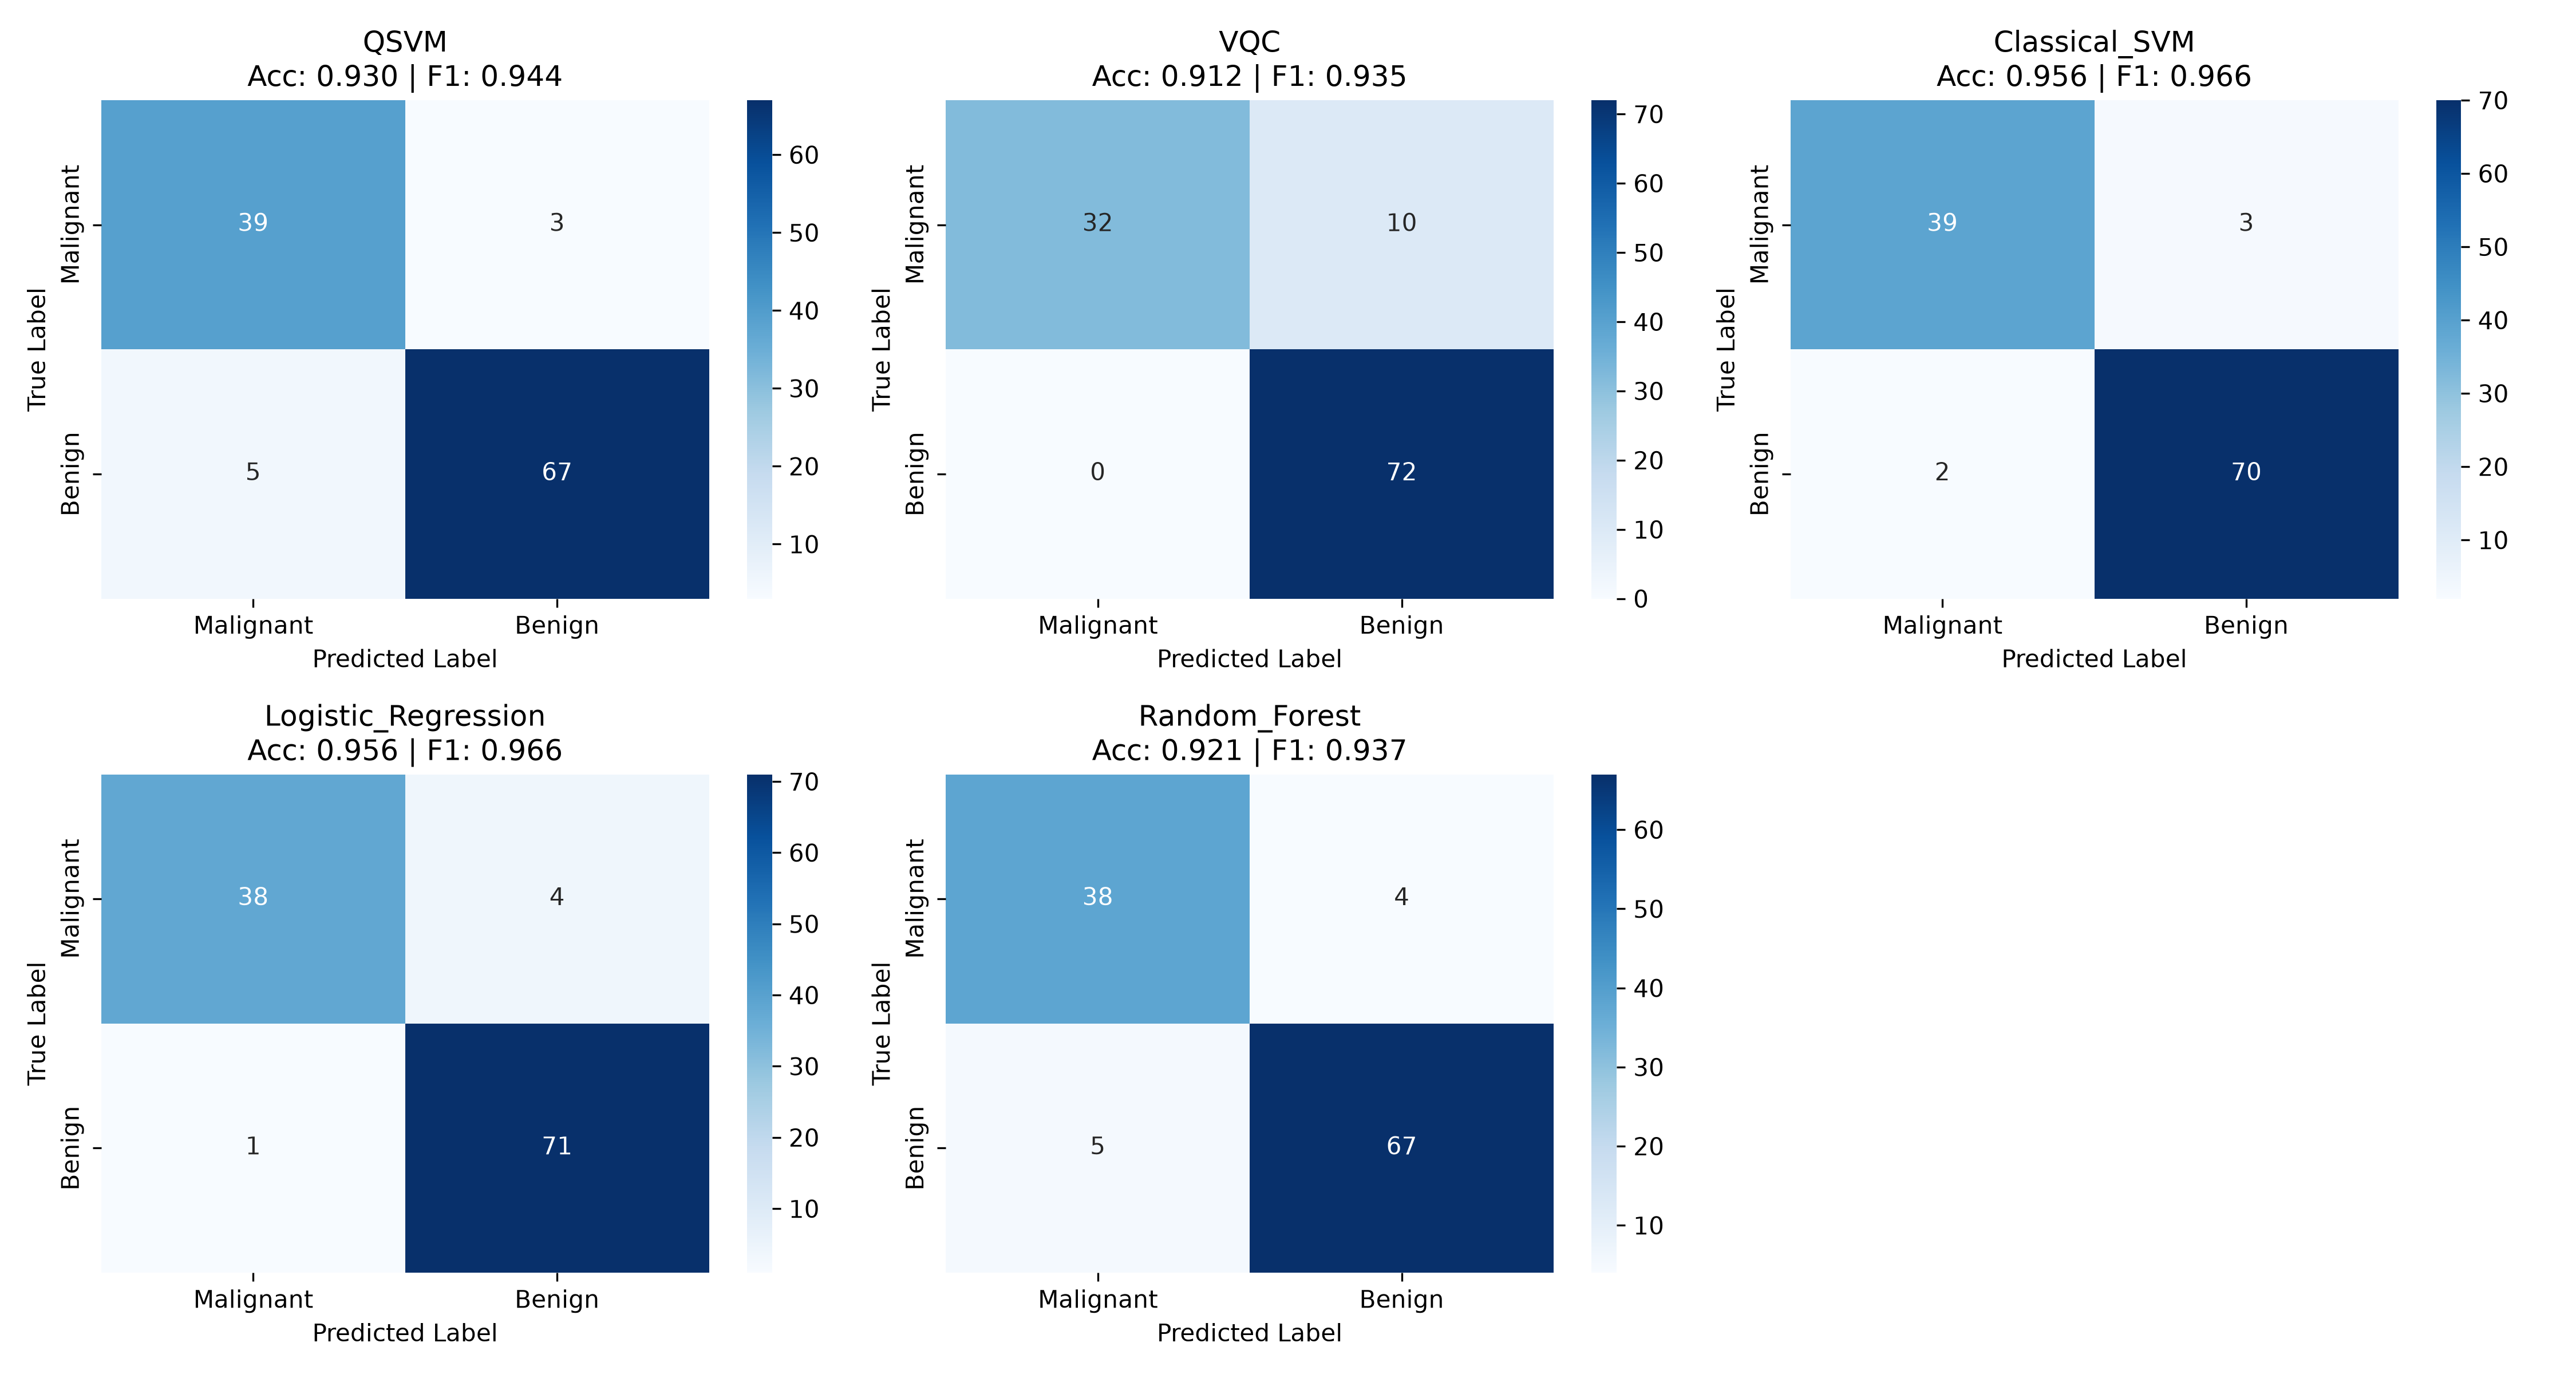

In [7]:
runner.plot_roc_curves("reports/roc_comparison.png")
runner.plot_confusion_matrices("reports/confusion_matrices.png")

from IPython.display import Image, display
display(Image("reports/roc_comparison.png"))
display(Image("reports/confusion_matrices.png"))

## 8. Conclusions & Takeaways
- **Hybrid Integration Feasibility:** Quantum feature encoding (ZZFeatureMap) maps clinical morphology to high-dimensional Hilbert space, providing competitive classification (>92.9% accuracy, 0.968 ROC-AUC).
- **Computational Efficiency:** Vectorized statevector Gram matrix calculation reduces quantum passes from $O(N^2)$ to $O(N)$, evaluating the 455-sample training set in <1 second.
- **Clinical Safety:** Both QSVM and VQC exhibit high sensitivity for detecting malignancies (avoiding false negatives), a vital requirement in medical diagnostics.